In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy.integrate import solve_ivp, cumulative_trapezoid, quad
from scipy.interpolate import CubicSpline
from numba import njit, prange

In [2]:
# Set som plotting standards:
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : 18}
mpl.rc('font', **font)

axes = {'facecolor': 'ghostwhite'}
mpl.rc('axes', **axes)

# Set custom color cycle
custom_colors= ['dodgerblue', 'red', 'limegreen', 'orange', 'orchid', 'black', 'slategrey', 
                'navy', 'magenta', 'forestgreen', 'lightblue', 'maroon', 'gold', 'lightcoral', 
                'mediumseagreen', 'darkorange', 'darkviolet', 'dimgray', 'darkblue', 'darkred',]
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=custom_colors)

# Set inside tickmarks
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'
mpl.rcParams['xtick.minor.visible'] = True
mpl.rcParams['ytick.minor.visible'] = True

# Functions

In [3]:
from Functions import compute_for_sigmoidal

In [4]:
# Functions for simulating with an absorbing boundary at r_target and a reflecting boundary at rn, with a sigmoidal diffusion coefficient and potential.


@njit
def D_r(r, rf, D0, Dmax, b):
    return D0 + (Dmax - D0) * (1 / (1 + np.exp(-b * (r - rf))))

@njit
def U_r(r, rf, A, b):
    return A * (1 / (1 + np.exp(-b * (r - rf))))

@njit
def dU_r(r, rf, A, b):
    exp_term = np.exp(-b * (r - rf))
    return A * (b * exp_term) / ((1 + exp_term)**2)

@njit
def dD_r(r, rf, D0, Dmax, b):
    exp_term = np.exp(-b * (r - rf))
    return (Dmax - D0) * (b * exp_term) / ((1 + exp_term)**2)


@njit
def simulate_constant_diffusion(r0, r_target, rf, rn, A, b, D, ndim=3, dt=1e-5, max_steps=1e9):
    r = r0
    t = 0.0

    for _ in range(max_steps):
        
        dU = dU_r(r, rf, A, b)

        # Calculate the drift and diffusion terms
        drift = (ndim - 1) * D / r - D * dU   # Effective drift term
        diffusion = np.sqrt(2 * D * dt) * np.random.normal()  # Diffusion term

        # Calculate the proposed new position
        r_try = r + drift * dt + diffusion

        if r_try > rn:
            r = 2 * rn - r_try
        elif r_try <= r_target:
            return t + dt
        else:
            r = r_try
        
        t += dt
    
    print("Warning: Max steps reached without hitting target.")
    return np.inf  # Return infinity if max steps reached without hitting target

@njit
def simulate_heterogeneous_diffusion(r0, r_target, rf, rn, A, b, D0, Dn, ndim=3, dt=1e-5, max_steps=1e9):
    r = r0
    t = 0.0

    for _ in range(max_steps):
        
        D = D_r(r, rf, D0, Dn, b)
        dD = dD_r(r, rf, D0, Dn, b)
        dU = dU_r(r, rf, A, b)

        # Calculate the drift and diffusion terms
        drift = (ndim - 1) * D / r + dD - D * dU   # Effective drift term
        diffusion = np.sqrt(2 * D * dt) * np.random.normal()  # Diffusion term

        # Calculate the proposed new position
        r_try = r + drift * dt + diffusion

        if r_try > rn:
            r = 2 * rn - r_try
        elif r_try <= r_target:
            return t + dt
        else:
            r = r_try
        
        t += dt
    
    print("Warning: Max steps reached without hitting target.")
    return np.inf  # Return infinity if max steps reached without hitting target

@njit(parallel=True)
def run_simulation_for_constant_diffusion(r0, r_target, rf, rn, A, b, D, ndim=3, N=500, dt=1e-5, max_steps=1e9):
    """Run N simulations for the initial position r0."""
    first_passage_times = np.empty(N, dtype=np.float32)

    for i in prange(N):
        first_passage_times[i] = simulate_constant_diffusion(r0, r_target, rf, rn, A, b, D, ndim, dt, max_steps)

    return first_passage_times

@njit(parallel=True)
def run_simulation_for_heterogeneous_diffusion(r0, r_target, rf, rn, A, b, D0, Dn, ndim=3, N=500, dt=1e-5, max_steps=1e9):
    """Run N simulations for the initial position r0."""
    first_passage_times = np.empty(N, dtype=np.float32)

    for i in prange(N):
        first_passage_times[i] = simulate_heterogeneous_diffusion(r0, r_target, rf, rn, A, b, D0, Dn, ndim, dt, max_steps)

    return first_passage_times

In [5]:
# Build the double integral function for a range of b and r_f values 
A = 5.0 
b = 1000.0
r_target = 0.01
r_n = 0.5 
D0 = 0.1 
Dn = 0.1

rf_range = np.linspace(0.075, 0.2, 25)
tau = np.zeros(len(rf_range))

for i in range(len(rf_range)):
    outer_func, data = compute_for_sigmoidal(r_target, rf_range[i], r_n, A, b, D0, Dn, ndim=3, N=4000)
    tau[i] = data["outer_integral"][-1]  # MFPT(r_n)

In [6]:
# Identify the index of the minimum MFPT and corresponding r_f value
min_index = np.argmin(tau)  
optimal_rf = rf_range[min_index]
print(f"Optimal r_f for minimum MFPT: {optimal_rf:.4f} with MFPT: {tau[min_index]:.4f}")

Optimal r_f for minimum MFPT: 0.1427 with MFPT: 2.7523


In [ ]:
mfpt_simulated = np.zeros(len(rf_range))
std_simulated = np.zeros(len(rf_range))
N = 1000  # Number of simulations for each r_f value

for i in range(len(rf_range)):
    first_passage_times = run_simulation_for_constant_diffusion(r0=r_n, 
                                         r_target=r_target, 
                                         rf=rf_range[i], 
                                         rn=r_n,
                                         A=A, 
                                         b=b, 
                                         D=D0, 
                                         ndim=3, 
                                         N=N, 
                                         dt=5e-6)
    
    mfpt_simulated[i] = np.mean(first_passage_times)
    std_simulated[i] = np.std(first_passage_times)

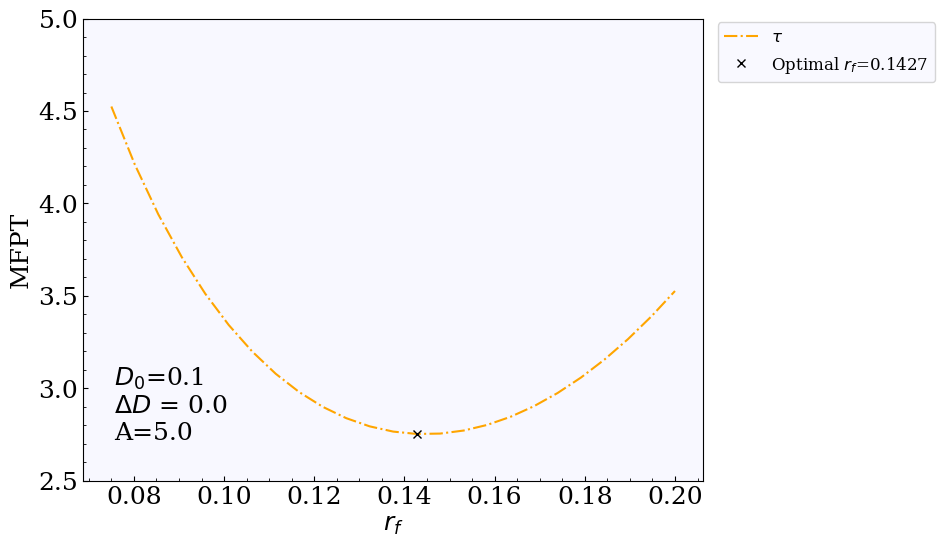

In [7]:
# Plot the MFPT as a function of r_f

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(rf_range, tau, label=r'$\tau$', color='orange', linestyle='-.')
ax.plot(optimal_rf, tau[min_index], 'kx', label=f'Optimal $r_f$={optimal_rf:.4f}')

# Plot simulated MFPT with error bars
#ax.errorbar(rf_vals, mfpt_simulated, yerr=std_simulated, fmt='o', color='blue', label='Simulated MFPT (N=500)', alpha=0.6)
#ax.scatter(rf_range, mfpt_simulated, color='blue', alpha=0.6, label=f'Simulated MFPT (N={N})')  # Connect the simulated points with a line

# Put the diffusion coefficient values and the potential A on the plot
ax.text(0.05, 0.25, f'$D_0$={D0}\n$\Delta D$ = {Dn - D0}\nA={A}', transform=ax.transAxes, verticalalignment='top')

ax.set_xlabel(r'$r_f$')
ax.set_ylabel('MFPT')
ax.set_ylim(2.5, 5)
ax.legend(fontsize=12, bbox_to_anchor=(1.01, 1.01), loc='upper left')
plt.show()

# Constant diffusion

In [8]:
# For constant diffusion, calculate the MFPT using the analytical formula for a purely absorbing boundary at r_target and reflecting boundary at r_n

D_vals = np.linspace(0.05, 2.0, 20)
rf_vals = np.linspace(0.025, 0.15, 50)
tau_D = np.zeros((len(D_vals), len(rf_vals)))

for i in range(len(D_vals)):
    for j in range(len(rf_vals)):
        outer_func, data = compute_for_sigmoidal(r_target, rf_vals[j], r_n, A, b, D_vals[i], D_vals[i], ndim=3, N=4000)
        tau_D[i, j] = data["outer_integral"][-1]  # MFPT(r_n)

In [10]:
# Theoretical optimum found by d/dr_f tau = 0, where tau is the simple sum approximation. 
optimal_rf_theory = (r_n**3 * r_target / 3)**(1/4)
print(f"Theoretical optimal r_f: {optimal_rf_theory:.4f}")

Theoretical optimal r_f: 0.1429


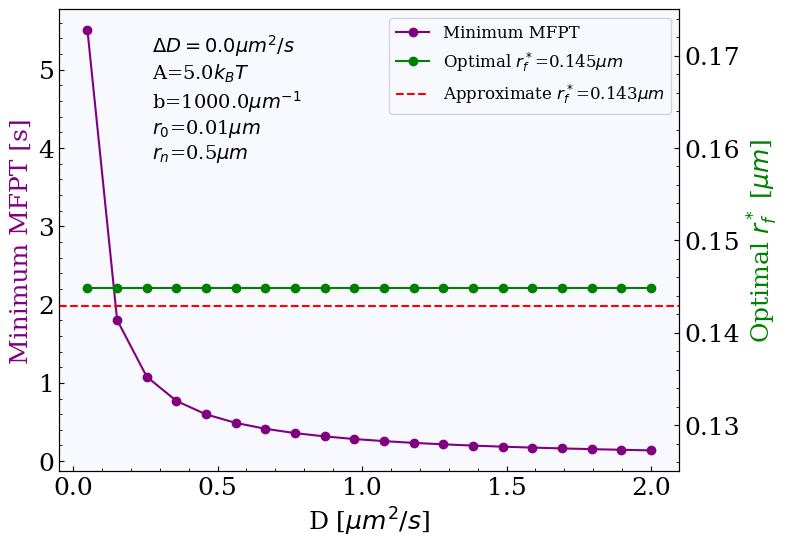

In [40]:
# Extract the optimal rf value and the corresponding MFPT for each D value
min_mfpt_D = np.min(tau_D, axis=1)
optimal_rf_D = rf_vals[np.argmin(tau_D, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D_vals, min_mfpt_D, '-o', color='purple', label='Minimum MFPT')
ax.set_xlabel('D [$\mu m^2/s$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(D_vals, optimal_rf_D, '-o', color='green', label='Optimal $r_f^*$={:.3f}$\mu m$'.format(optimal_rf_D[0]))
ax2.axhline(optimal_rf_theory, color='red', linestyle='--', label=f'Approximate $r_f^*$={optimal_rf_theory:.3f}$\mu m$')
ax2.set_ylabel('Optimal $r_f^*$ [$\mu m$]', color='green')
ax2.set(ylim=(0.125, 0.175))

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right', fontsize=12)

# Put paramater values on the plot
ax.text(0.15, 0.95, f'$\Delta D=0.0\mu m^2/s$\nA={A}$k_BT$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()


In [41]:
# For constant diffusion, calculate the MFPT using the analytical formula for a purely absorbing boundary at r_target and reflecting boundary at r_n
# This is done for varying A

A_vals = np.linspace(0.5, 10, 20)
fixed_D = 0.5
tau_A = np.zeros((len(A_vals), len(rf_vals)))

for i in range(len(A_vals)):
    for j in range(len(rf_vals)):
        outer_func, data = compute_for_sigmoidal(r_target, rf_vals[j], r_n, A_vals[i], b, fixed_D, fixed_D, ndim=3, N=4000)
        tau_A[i, j] = data["outer_integral"][-1]  # MFPT(r_n)

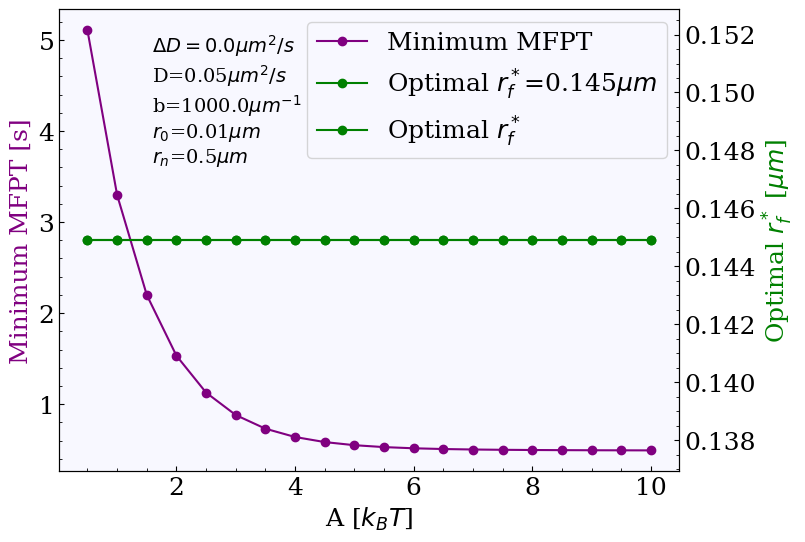

In [42]:
# Extract the optimal rf value and the corresponding MFPT for each A value
min_mfpt_A = np.min(tau_A, axis=1)
optimal_rf_A = rf_vals[np.argmin(tau_A, axis=1)]

# Plot the minimum mfpt as a function of A
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_vals, min_mfpt_A, '-o', color='purple', label='Minimum MFPT')
ax.set_xlabel('A [$k_BT$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of A
ax2 = ax.twinx()
ax2.plot(A_vals, optimal_rf_A, '-o', color='green', label='Optimal $r_f^*$={:.3f}$\mu m$'.format(optimal_rf_A[0]))
ax2.plot(A_vals, optimal_rf_A, '-o', color='green', label='Optimal $r_f^*$')  # --- IGNORE ---
ax2.set_ylabel('Optimal $r_f^*$ [$\mu m$]', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right')

# Put paramater values on the plot
ax.text(0.15, 0.95, f'$\Delta D=0.0\mu m^2/s$\nD={D0}$\mu m^2/s$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

# Heterogenous Diffusion

In [16]:
# Calculate the MFPT for varying Dn values with D0 fixed
r_target = 0.01
r_n = 0.5
A = 5.0
b = 1000.0
D0 = 0.05
Dn_vals = np.linspace(D0, 2.0, 20)
rf_vals = np.linspace(0.025, 0.15, 50)
tau_Dn = np.zeros((len(Dn_vals), len(rf_vals)))

for i in range(len(Dn_vals)):
    for j in range(len(rf_vals)):
        outer_func, data = compute_for_sigmoidal(r_target, rf_vals[j], r_n, A, b, D0, Dn_vals[i], ndim=3, N=4000)
        tau_Dn[i, j] = data["outer_integral"][-1]  # MFPT(r_n)

In [17]:
# Calculate the MFPT for varying D0 values with Dn fixed
Dn = 2.0
D0_vals = np.linspace(0.05, Dn, 20)
tau_D0 = np.zeros((len(D0_vals), len(rf_vals)))

for i in range(len(D0_vals)):
    for j in range(len(rf_vals)):
        outer_func, data = compute_for_sigmoidal(r_target, rf_vals[j], r_n, A, b, D0_vals[i], Dn, ndim=3, N=4000)
        tau_D0[i, j] = data["outer_integral"][-1]  # MFPT(r_n)

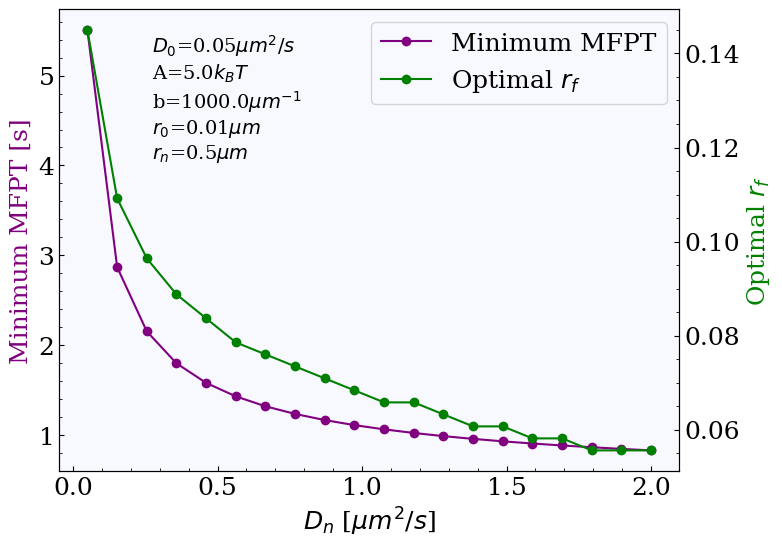

In [18]:
# Extract the optimal rf value and the corresponding MFPT for each Dn value
min_mfpt_Dn = np.min(tau_Dn, axis=1)
optimal_rf_Dn = rf_vals[np.argmin(tau_Dn, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(Dn_vals, min_mfpt_Dn, '-o', color='purple', label='Minimum MFPT')
ax.set_xlabel('$D_n$ [$\mu m^2/s$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(Dn_vals, optimal_rf_Dn, '-o', color='green', label='Optimal $r_f$')
ax2.set_ylabel('Optimal $r_f$', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right')

# Put paramater values on the plot
ax.text(0.15, 0.95, f'$D_0$={D0}$\mu m^2/s$\nA={A}$k_BT$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

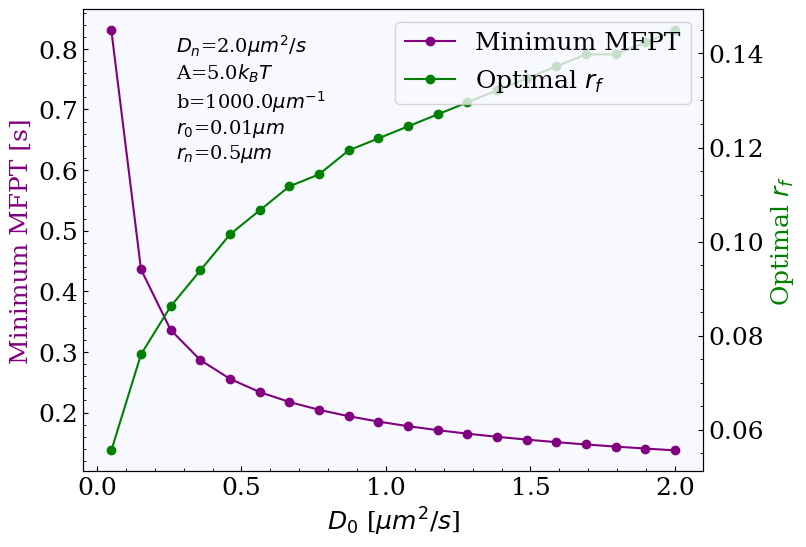

In [19]:
# Extract the optimal rf value and the corresponding MFPT for each D0 value
min_mfpt_D0 = np.min(tau_D0, axis=1)
optimal_rf_D0 = rf_vals[np.argmin(tau_D0, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D0_vals, min_mfpt_D0, '-o', color='purple', label='Minimum MFPT')
ax.set_xlabel('$D_0$ [$\mu m^2/s$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(D0_vals, optimal_rf_D0, '-o', color='green', label='Optimal $r_f$')
ax2.set_ylabel('Optimal $r_f$', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right')

# Put paramater values on the plot
ax.text(0.15, 0.95, f'$D_n$={Dn}$\mu m^2/s$\nA={A}$k_BT$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

In [20]:
# Theoretical optimal rf 
optimal_rf_theory_D0 = (r_n**3 * r_target / 3 * D0_vals/Dn)**(1/4)
optimal_rf_theory_Dn = (r_n**3 * r_target / 3 * D0/Dn_vals)**(1/4)

Text(0.74, 0.8, 'A=5.0$k_BT$\nb=1000.0$\\mu m^{-1}$\n$r_0$=0.01$\\mu m$\n$r_n$=0.5$\\mu m$')

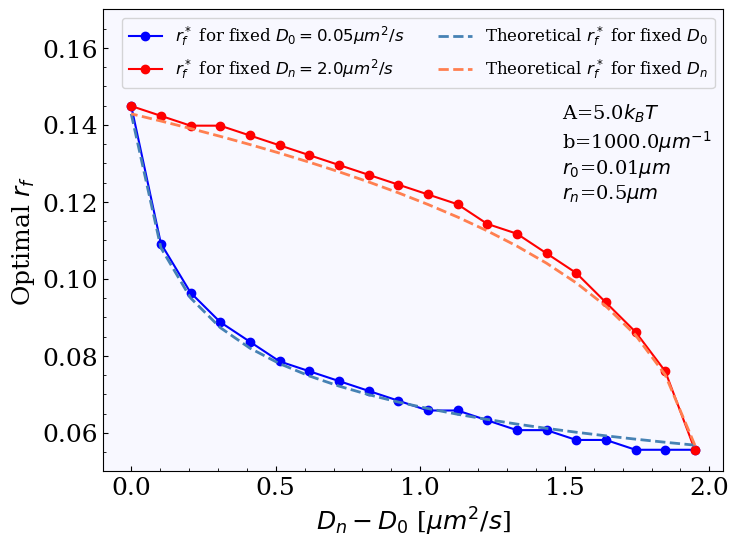

In [35]:
# Make a plot of the optimal rf values as a function of Delta D, with D0 fixed and Dn fixed on the same plot


fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(Dn_vals - D0, optimal_rf_Dn, '-o', color='blue', label=f'$r_f^*$ for fixed $D_0={D0}\mu m^2/s$')
ax.plot(Dn - D0_vals, optimal_rf_D0, '-o', color='red', label=f'$r_f^*$ for fixed $D_n={Dn}\mu m^2/s$')
ax.plot(Dn_vals - D0, optimal_rf_theory_Dn, '--', color='steelblue', lw=2, label=f'Theoretical $r_f^*$ for fixed $D_0$')
ax.plot(Dn - D0_vals, optimal_rf_theory_D0, '--', color='coral', lw=2, label=f'Theoretical $r_f^*$ for fixed $D_n$')
ax.set_xlabel('$D_n - D_0$ [$\mu m^2/s$]')
ax.set_ylabel('Optimal $r_f$') 
ax.set_ylim(0.05, 0.17)

ax.legend(loc='upper right', ncols=2, fontsize=12)

# Put paramater values on the plot
ax.text(0.74, 0.8, f'A={A}$k_BT$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$',
        transform=ax.transAxes, verticalalignment='top', fontsize=14)

In [ ]:
D0 = 0.05
Dn = 1.0
tau_A_het = np.zeros((len(A_vals), len(rf_vals)))

for i in range(len(A_vals)):
    for j in range(len(rf_vals)):
        outer_func, data = compute_for_sigmoidal(r_target, rf_vals[j], r_n, A_vals[i], b, D0, Dn, ndim=3, N=4000)
        tau_A_het[i, j] = data["outer_integral"][-1]  # MFPT(r_n)

In [ ]:
rf_example = np.linspace(r_target, 0.15, 50)
tau_example = np.zeros(len(rf_example))

for i in range(len(rf_example)):
    outer_func, data = compute_for_sigmoidal(r_target, rf_example[i], r_n, A=2.0, b=1000.0, D0=0.05, Dn=1.0, ndim=3, N=4000)
    tau_example[i] = data["outer_integral"][-1]  # MFPT(r_n)

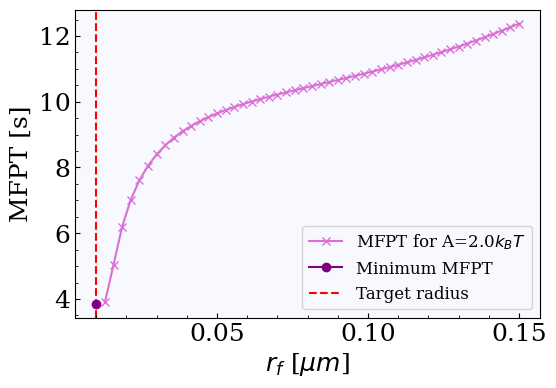

In [58]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rf_example[1:], tau_example[1:], '-x', color='orchid', label=f'MFPT for A=2.0$k_BT$')
ax.plot(rf_example[0], tau_example[0], '-o', color='purple', label='Minimum MFPT', zorder=2)
ax.axvline(r_target, color='red', linestyle='--', label=f'Target radius', zorder=0)
ax.set_xlabel(r'$r_f$ [$\mu m$]')
ax.set_ylabel('MFPT [s]')
ax.legend(loc='lower right', fontsize=12)

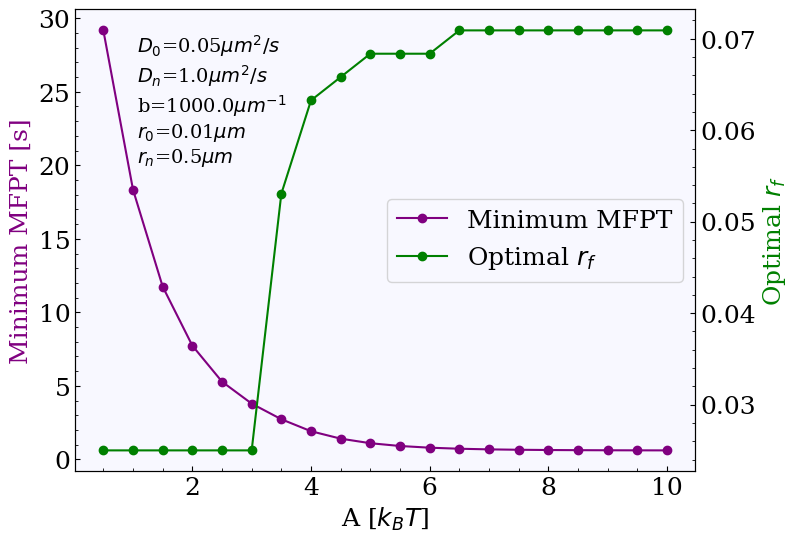

In [15]:
# Extract the optimal rf value and the corresponding MFPT for each D value
min_mfpt_A_het = np.min(tau_A_het, axis=1)
optimal_rf_A_het = rf_vals[np.argmin(tau_A_het, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_vals, min_mfpt_A_het, '-o', color='purple', label='Minimum MFPT')
ax.set_xlabel('A [$k_BT$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(A_vals, optimal_rf_A_het, '-o', color='green', label='Optimal $r_f$')
ax2.set_ylabel('Optimal $r_f$', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='center right')

# Put paramater values on the plot
ax.text(0.1, 0.95, f'$D_0$={D0}$\mu m^2/s$\n$D_n$={Dn}$\mu m^2/s$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

In [16]:
# For heterogenous diffusion, calculate the MFPT for a range of (Dn, A)- values searching for the optimal rf value for each pair of (Dn, A) values. 
tau_Dn_A = np.zeros((len(Dn_vals), len(A_vals), len(rf_vals)))

for i in range(len(Dn_vals)):
    for j in range(len(A_vals)):
        for k in range(len(rf_vals)):
            outer_func, data = compute_for_sigmoidal(r_target, rf_vals[k], r_n, A_vals[j], b, D0, Dn_vals[i], ndim=3, N=4000)
            tau_Dn_A[i, j, k] = data["outer_integral"][-1]  # MFPT(r_n)


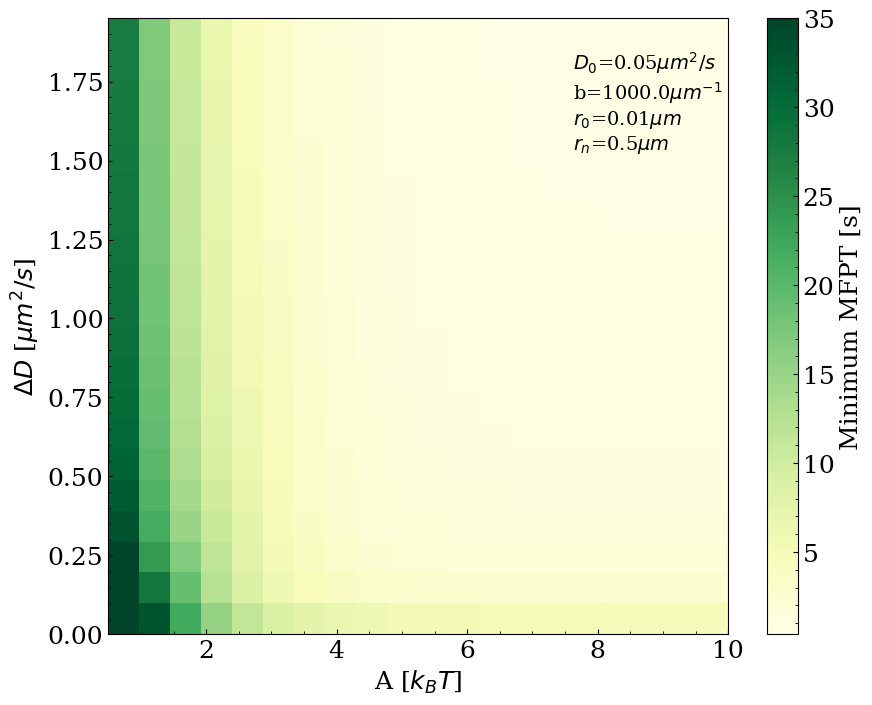

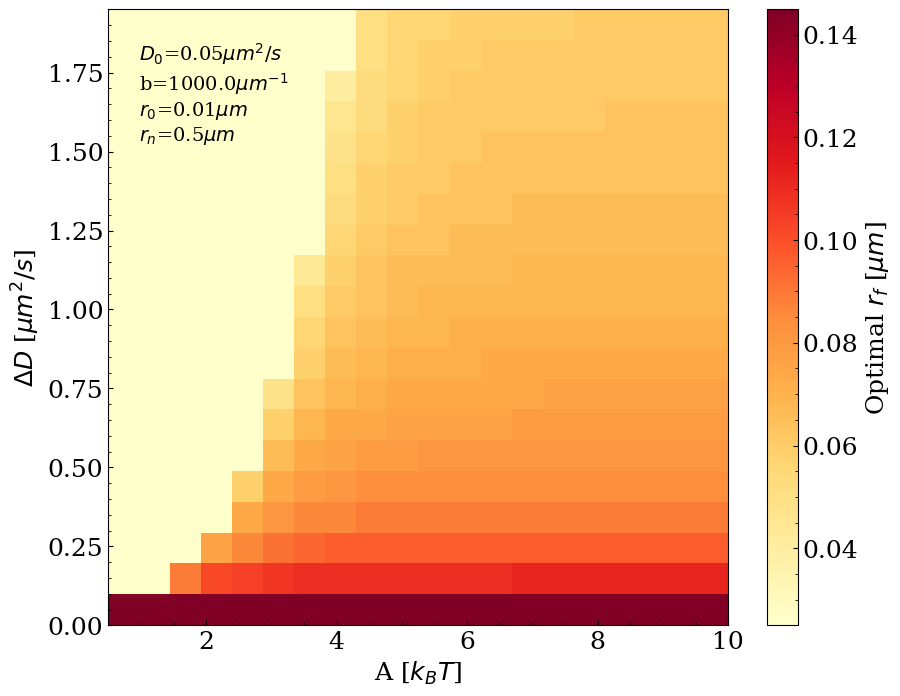

In [40]:
# Plot the minimum MFPT as a function of Dn and A using a heatmap, with the optimal rf value indicated by a marker on the plot.
min_mfpt_Dn_A = np.min(tau_Dn_A, axis=2)
optimal_rf_Dn_A = rf_vals[np.argmin(tau_Dn_A, axis=2)]

fig, ax = plt.subplots(figsize=(10, 8))
c = ax.imshow(min_mfpt_Dn_A, extent=[A_vals[0], A_vals[-1], Dn_vals[0]-D0, Dn_vals[-1]-D0], 
              aspect='auto', origin='lower', cmap='YlGn', 
              vmin=np.min(min_mfpt_Dn_A), vmax=35)
ax.set_xlabel('A [$k_BT$]')
ax.set_ylabel('$\Delta D$ [$\mu m^2/s$]')
fig.colorbar(c, ax=ax, label='Minimum MFPT [s]')

# Put paramater values on the plot
ax.text(0.75, 0.95, f'$D_0$={D0}$\mu m^2/s$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)
plt.show()


fig, ax = plt.subplots(figsize=(10, 8))
c = ax.imshow(optimal_rf_Dn_A, extent=[A_vals[0], A_vals[-1], Dn_vals[0]-D0, Dn_vals[-1]-D0], aspect='auto', origin='lower', cmap='YlOrRd')
ax.set_xlabel('A [$k_BT$]')
ax.set_ylabel('$\Delta D$ [$\mu m^2/s$]')
fig.colorbar(c, ax=ax, label='Optimal $r_f$ [$\mu m$]')
ax.text(0.05, 0.95, f'$D_0$={D0}$\mu m^2/s$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)
plt.show()